In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Load Fashion-MNIST
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

print("Training:", X_train_full.shape, y_train_full.shape)
print("Test:", X_test.shape, y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training: (60000, 28, 28) (60000,)
Test: (10000, 28, 28) (10000,)


In [ ]:
# Shuffle the training data
indices = np.random.permutation(len(X_train_full))

X_train_full = X_train_full[indices]
y_train_full = y_train_full[indices]

# Split
X_train = X_train_full[:48000]
y_train = y_train_full[:48000]

X_calib = X_train_full[48000:]
y_calib = y_train_full[48000:]

print("Training:", X_train.shape, y_train.shape)
print("Calibration:", X_calib.shape, y_calib.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (48000, 28, 28) (48000,)
Calibration: (12000, 28, 28) (12000,)
Test: (10000, 28, 28) (10000,)


In [ ]:
X_train=X_train.astype("float32")/255.0
X_calib=X_calib.astype("float32")/255.0
X_test=X_test.astype("float32")/255.0

In [ ]:
X_train = X_train[..., np.newaxis]
X_calib = X_calib[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print(X_train.shape)

(48000, 28, 28, 1)


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
model=models.Sequential([
    layers.Conv2D(32,(3,3),activation="relu",input_shape=(28,28,1)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128,activation="relu"),
    layers.Dense(10,activation="softmax")
])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from IPython.core import history
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
history=model.fit(X_train,y_train,epochs=10,batch_size=64,validation_data=(X_calib,y_calib))

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.8125 - loss: 0.5199 - val_accuracy: 0.8585 - val_loss: 0.3911
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8761 - loss: 0.3430 - val_accuracy: 0.8719 - val_loss: 0.3464
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8949 - loss: 0.2913 - val_accuracy: 0.8888 - val_loss: 0.3047
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9050 - loss: 0.2598 - val_accuracy: 0.8932 - val_loss: 0.2868
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9139 - loss: 0.2344 - val_accuracy: 0.8921 - val_loss: 0.2888
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9229 - loss: 0.2096 - val_accuracy: 0.8930 - val_loss: 0.2940
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9295 - loss: 0.1907 - val_accuracy: 0.8951 - val_loss: 0.2900
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9358 - loss: 0.1731 - val_accuracy: 0

In [ ]:
test_loss, test_accuracy = model.evaluate (X_test,y_test,verbose=0)
print("test loss:",test_loss)
print("accuracy :",test_accuracy)

test loss: 0.27724841237068176
accuracy : 0.9060999751091003


In [ ]:
probs = model.predict(X_test)
print(probs.shape)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
(10000, 10)


In [ ]:
i = 0

print("True class:", y_test[i])
print("Probabilities:", probs[i])
print("Predicted class:", np.argmax(probs[i]))
print("Confidence:", np.max(probs[i]))

True class: 9
Probabilities: [9.54913389e-07 9.28492661e-09 2.90187305e-08 1.16942594e-07
 1.53179315e-07 2.88508927e-05 3.23788669e-07 9.00949672e-05
 1.97801705e-06 9.99877453e-01]
Predicted class: 9
Confidence: 0.99987745


In [ ]:
y_pred = np.argmax(probs, axis=1)

print(y_pred[:20])
print(y_test[:20])

[9 2 1 1 6 1 4 6 5 7 4 5 7 3 4 1 2 4 8 0]
[9 2 1 1 6 1 4 6 5 7 4 5 7 3 4 1 2 4 8 0]


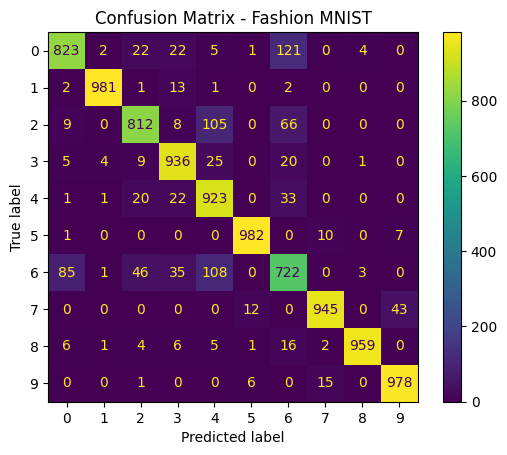

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Confusion Matrix - Fashion MNIST")
plt.show()

In [ ]:
confidence = np.max(probs, axis=1)
correct = y_pred == y_test

In [ ]:
correct_indices = np.where(correct)[0]

# Sort correct examples by confidence
sorted_correct = correct_indices[
    np.argsort(confidence[correct_indices])[::-1]
]

top_correct = sorted_correct[:5]

print(top_correct)
print(confidence[top_correct])

[4710 9931 9990   64    2]
[1. 1. 1. 1. 1.]


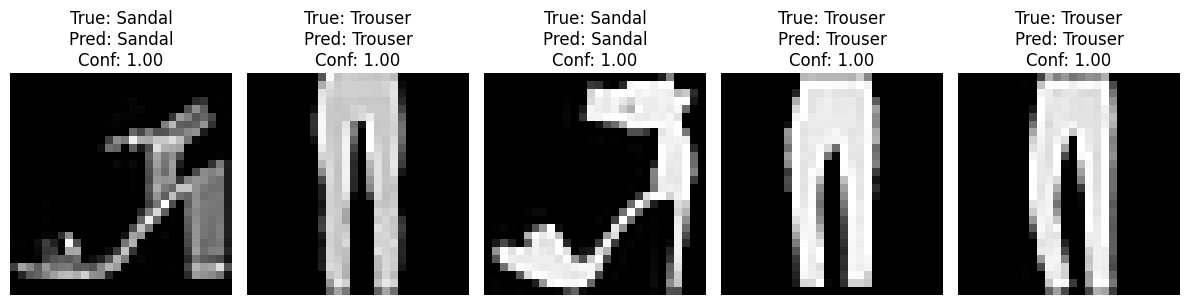

In [ ]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

plt.figure(figsize=(12, 4))

for j, idx in enumerate(top_correct):
    plt.subplot(1, 5, j + 1)

    plt.imshow(X_test[idx].squeeze(), cmap="gray")
    plt.title(
        f"True: {class_names[y_test[idx]]}\n"
        f"Pred: {class_names[y_pred[idx]]}\n"
        f"Conf: {confidence[idx]:.2f}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
wrong_indices = np.where(~correct)[0]

sorted_wrong = wrong_indices[
    np.argsort(confidence[wrong_indices])[::-1]
]

top_wrong = sorted_wrong[:5]

print(top_wrong)
print(confidence[top_wrong])

[6472 2914   23  787 9238]
[0.9999887  0.9999361  0.99988425 0.9998716  0.9997391 ]


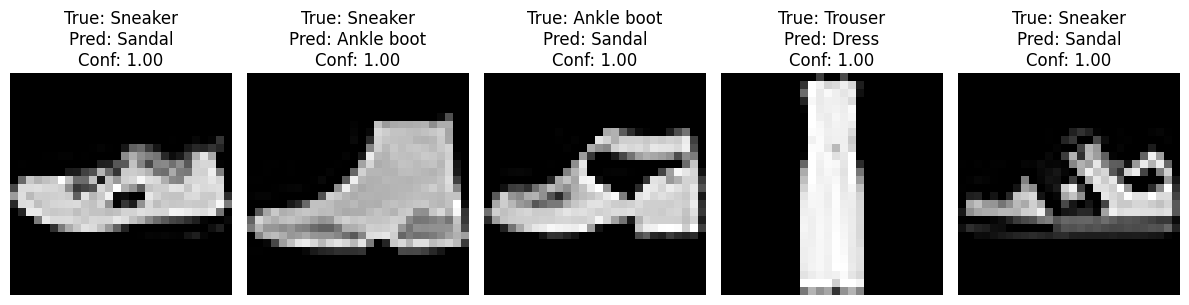

In [ ]:
plt.figure(figsize=(12, 4))

for j, idx in enumerate(top_wrong):
    plt.subplot(1, 5, j + 1)

    plt.imshow(X_test[idx].squeeze(), cmap="gray")
    plt.title(
        f"True: {class_names[y_test[idx]]}\n"
        f"Pred: {class_names[y_pred[idx]]}\n"
        f"Conf: {confidence[idx]:.2f}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
ambiguous_indices = np.argsort(confidence)[:5]

for idx in ambiguous_indices:
    print("\nImage:", idx)
    print("True class:", class_names[y_test[idx]])
    print("Predicted:", class_names[y_pred[idx]])
    print("Confidence:", confidence[idx])

    for k, p in enumerate(probs[idx]):
        print(f"  {class_names[k]:12s}: {p:.4f}")


Image: 2343
True class: Bag
Predicted: Shirt
Confidence: 0.21953748
  T-shirt/top : 0.0803
  Trouser     : 0.0000
  Pullover    : 0.0295
  Dress       : 0.1513
  Coat        : 0.1971
  Sandal      : 0.1168
  Shirt       : 0.2195
  Sneaker     : 0.0033
  Bag         : 0.2012
  Ankle boot  : 0.0010

Image: 2842
True class: Shirt
Predicted: Coat
Confidence: 0.24427475
  T-shirt/top : 0.1099
  Trouser     : 0.0000
  Pullover    : 0.1265
  Dress       : 0.2148
  Coat        : 0.2443
  Sandal      : 0.0000
  Shirt       : 0.2283
  Sneaker     : 0.0000
  Bag         : 0.0760
  Ankle boot  : 0.0001

Image: 8764
True class: Dress
Predicted: T-shirt/top
Confidence: 0.25538468
  T-shirt/top : 0.2554
  Trouser     : 0.0014
  Pullover    : 0.0987
  Dress       : 0.2514
  Coat        : 0.1956
  Sandal      : 0.0000
  Shirt       : 0.1973
  Sneaker     : 0.0000
  Bag         : 0.0001
  Ankle boot  : 0.0000

Image: 5745
True class: T-shirt/top
Predicted: Shirt
Confidence: 0.2788008
  T-shirt/top : 0.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

n_bins = 10

bin_edges = np.linspace(0, 1, n_bins + 1)

print(bin_edges)

[0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]


In [ ]:
bin_confidence = []
bin_accuracy = []
bin_count = []

In [ ]:
for i in range(n_bins):

    # Select predictions belonging to this bin
    if i == n_bins - 1:
        mask = (confidence >= bin_edges[i]) & (confidence <= bin_edges[i + 1])
    else:
        mask = (confidence >= bin_edges[i]) & (confidence < bin_edges[i + 1])

    # Number of examples in this bin
    count = np.sum(mask)

    bin_count.append(count)

    # If the bin is empty
    if count == 0:
        bin_confidence.append(np.nan)
        bin_accuracy.append(np.nan)
        continue

    # Average confidence in the bin
    avg_conf = np.mean(confidence[mask])

    # Accuracy in the bin
    acc = np.mean(y_pred[mask] == y_test[mask])

    bin_confidence.append(avg_conf)
    bin_accuracy.append(acc)

In [ ]:
for i in range(n_bins):
    print(
        f"Bin {i+1}: "
        f"count={bin_count[i]}, "
        f"confidence={bin_confidence[i]:.3f}, "
        f"accuracy={bin_accuracy[i]:.3f}"
    )

Bin 1: count=0, confidence=nan, accuracy=nan
Bin 2: count=0, confidence=nan, accuracy=nan
Bin 3: count=5, confidence=0.258, accuracy=0.000
Bin 4: count=49, confidence=0.366, accuracy=0.408
Bin 5: count=121, confidence=0.459, accuracy=0.430
Bin 6: count=363, confidence=0.549, accuracy=0.485
Bin 7: count=365, confidence=0.651, accuracy=0.584
Bin 8: count=495, confidence=0.751, accuracy=0.685
Bin 9: count=625, confidence=0.857, accuracy=0.789
Bin 10: count=7977, confidence=0.990, accuracy=0.974


the model is overconfident

In [ ]:
ece = 0
N = len(y_test)

for i in range(n_bins):

    if bin_count[i] == 0:
        continue

    weight = bin_count[i] / N

    error = abs(bin_accuracy[i] - bin_confidence[i])

    ece += weight * error

print(f"ECE: {ece:.4f}")

ECE: 0.0258


The model has an ECE of approximately 3.21%. This indicates a relatively small average discrepancy between confidence and empirical accuracy, although ECE depends on the chosen binning.

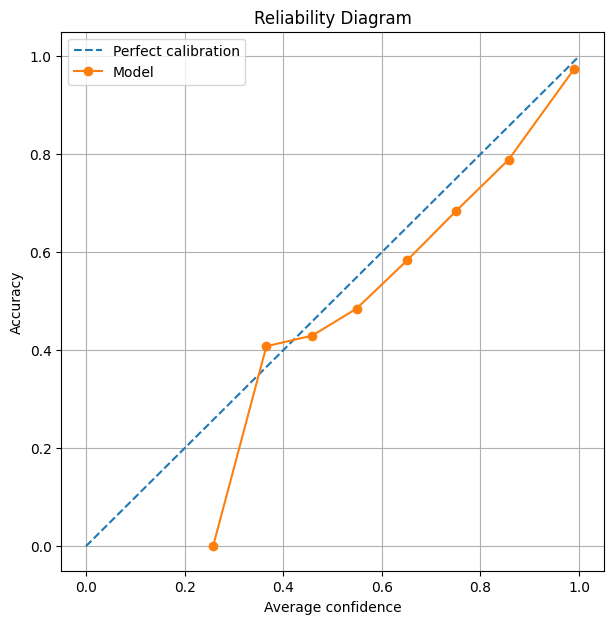

In [ ]:
plt.figure(figsize=(7, 7))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.plot(
    bin_confidence,
    bin_accuracy,
    marker="o",
    label="Model"
)

plt.xlabel("Average confidence")
plt.ylabel("Accuracy")
plt.title("Reliability Diagram")
plt.legend()
plt.grid()

plt.show()

we can see in the diagramme that the model is below the perfect callibration line so the model is a little bit overconfident

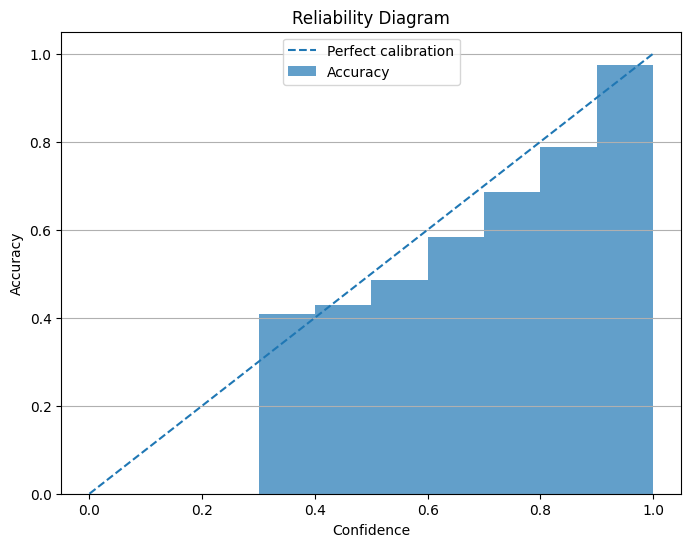

In [ ]:
plt.figure(figsize=(8, 6))

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

plt.bar(
    bin_centers,
    bin_accuracy,
    width=0.1,
    alpha=0.7,
    label="Accuracy"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Confidence")
plt.ylabel("Accuracy")
plt.title("Reliability Diagram")
plt.legend()
plt.grid(axis="y")

plt.show()

The reliability diagram shows those differences visually, while ECE summarizes them into one number.

In [ ]:
model_logits = models.Sequential([
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10)   ])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model_logits.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

history = model_logits.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_data=(X_calib, y_calib)
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.7932 - loss: 0.5800 - val_accuracy: 0.8479 - val_loss: 0.4281
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8673 - loss: 0.3710 - val_accuracy: 0.8608 - val_loss: 0.3740
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8836 - loss: 0.3210 - val_accuracy: 0.8847 - val_loss: 0.3231
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8961 - loss: 0.2866 - val_accuracy: 0.8905 - val_loss: 0.2985
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9043 - loss: 0.2608 - val_accuracy: 0.8940 - val_loss: 0.2817
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9118 - loss: 0.2404 - val_accuracy: 0.8901 - val_loss: 0.2974
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9173 - loss: 0.2228 - val_accuracy: 0.9029 - val_loss: 0.2624
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9239 - loss: 0.2068 - val_accuracy: 0

In [ ]:
calib_logits = model_logits.predict(X_calib)
test_logits = model_logits.predict(X_test)

print(calib_logits.shape)
print(test_logits.shape)

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
(12000, 10)
(10000, 10)


In [ ]:
def temperature_softmax(logits, T):
    return tf.nn.softmax(logits / T, axis=1).numpy()
i = 0

for T in [0.5, 1.0, 2.0, 3.0]:
    p = temperature_softmax(calib_logits[i:i+1], T)

    print(f"\nT = {T}")
    print(np.round(p[0], 4))
    print("Prediction:", np.argmax(p[0]))
    print("Confidence:", np.max(p[0]))


T = 0.5
[0.000e+00 0.000e+00 1.000e-04 0.000e+00 9.999e-01 0.000e+00 0.000e+00
 0.000e+00 0.000e+00 0.000e+00]
Prediction: 4
Confidence: 0.9998802

T = 1.0
[1.000e-04 0.000e+00 1.050e-02 0.000e+00 9.869e-01 0.000e+00 2.500e-03
 0.000e+00 0.000e+00 0.000e+00]
Prediction: 4
Confidence: 0.9869342

T = 2.0
[6.700e-03 8.000e-04 8.850e-02 2.200e-03 8.575e-01 0.000e+00 4.300e-02
 1.000e-04 5.000e-04 7.000e-04]
Prediction: 4
Confidence: 0.8574584

T = 3.0
[2.720e-02 6.600e-03 1.525e-01 1.290e-02 6.930e-01 4.000e-04 9.430e-02
 2.200e-03 5.100e-03 5.900e-03]
Prediction: 4
Confidence: 0.69300234


In [ ]:
def calculate_nll(logits, labels, T):
    scaled_logits = logits / T

    loss = tf.keras.losses.sparse_categorical_crossentropy(
        labels,
        scaled_logits,
        from_logits=True
    )

    return np.mean(loss.numpy())

In [ ]:
temperatures = np.linspace(0.5, 5.0, 46)

nll_values = []

for T in temperatures:
    nll = calculate_nll(calib_logits, y_calib, T)
    nll_values.append(nll)

best_index = np.argmin(nll_values)
best_T = temperatures[best_index]

print("Best temperature:", best_T)
print("Minimum calibration NLL:", nll_values[best_index])

Best temperature: 1.1
Minimum calibration NLL: 0.24429073145325636


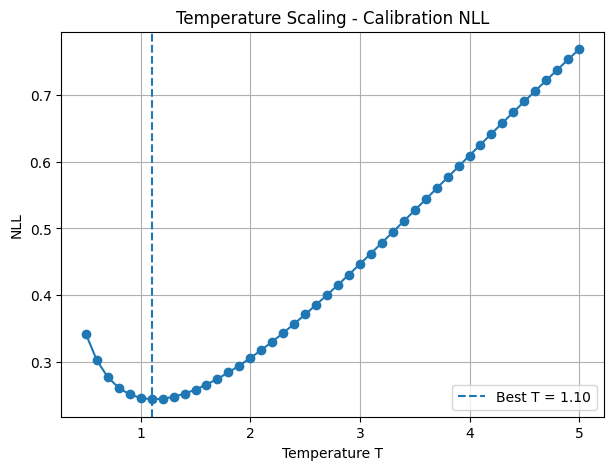

In [ ]:
plt.figure(figsize=(7, 5))

plt.plot(temperatures, nll_values, marker="o")

plt.axvline(
    best_T,
    linestyle="--",
    label=f"Best T = {best_T:.2f}"
)

plt.xlabel("Temperature T")
plt.ylabel("NLL")
plt.title("Temperature Scaling - Calibration NLL")
plt.legend()
plt.grid()

plt.show()

In [ ]:
test_probs_original = tf.nn.softmax(
    test_logits,
    axis=1
).numpy()

test_probs_scaled = temperature_softmax(
    test_logits,
    best_T
)

In [ ]:
pred_original = np.argmax(test_probs_original, axis=1)
pred_scaled = np.argmax(test_probs_scaled, axis=1)

acc_original = np.mean(pred_original == y_test)
acc_scaled = np.mean(pred_scaled == y_test)

print("Original accuracy:", acc_original)
print("Scaled accuracy:", acc_scaled)

Original accuracy: 0.9117
Scaled accuracy: 0.9117


In [ ]:
nll_original = calculate_nll(
    test_logits,
    y_test,
    1.0
)

nll_scaled = calculate_nll(
    test_logits,
    y_test,
    best_T
)

print("Original test NLL:", nll_original)
print("Scaled test NLL:", nll_scaled)

Original test NLL: 0.24638547
Scaled test NLL: 0.24419519599562273


In [ ]:
nll_original = calculate_nll(
    test_logits,
    y_test,
    1.0
)

nll_scaled = calculate_nll(
    test_logits,
    y_test,
    best_T
)

print("Original test NLL:", nll_original)
print("Scaled test NLL:", nll_scaled)

Original test NLL: 0.24638547
Scaled test NLL: 0.24419519599562273


In [ ]:
def calculate_ece(probs, labels, n_bins=10):

    predictions = np.argmax(probs, axis=1)
    confidence = np.max(probs, axis=1)

    bin_edges = np.linspace(0, 1, n_bins + 1)

    ece = 0.0

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence <= bin_edges[i + 1])
            )
        else:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence < bin_edges[i + 1])
            )

        count = np.sum(mask)

        if count == 0:
            continue

        bin_acc = np.mean(
            predictions[mask] == labels[mask]
        )

        bin_conf = np.mean(
            confidence[mask]
        )

        ece += (count / len(labels)) * abs(
            bin_acc - bin_conf
        )

    return ece

In [ ]:
ece_original = calculate_ece(
    test_probs_original,
    y_test
)

ece_scaled = calculate_ece(
    test_probs_scaled,
    y_test
)

print("Original ECE:", ece_original)
print("Scaled ECE:", ece_scaled)

Original ECE: 0.011598982611298585
Scaled ECE: 0.006000192447375186


In [ ]:
print("\nComparison")
print("-" * 45)
print(f"{'Metric':<15} {'Before':<12} {'After':<12}")
print("-" * 45)
print(f"{'Accuracy':<15} {acc_original:<12.4f} {acc_scaled:<12.4f}")
print(f"{'NLL':<15} {nll_original:<12.4f} {nll_scaled:<12.4f}")
print(f"{'ECE':<15} {ece_original:<12.4f} {ece_scaled:<12.4f}")


Comparison
---------------------------------------------
Metric          Before       After       
---------------------------------------------
Accuracy        0.9117       0.9117      
NLL             0.2464       0.2442      
ECE             0.0116       0.0060      


Temperature scaling leaves classification accuracy unchanged because it does not change the ordering of the logits. However, it can improve NLL and ECE by making the predicted probabilities better calibrated.

In [ ]:
calib_probs = tf.nn.softmax(
    calib_logits,
    axis=1
).numpy()

In [ ]:
true_class_probs = calib_probs[
    np.arange(len(y_calib)),
    y_calib
]

In [ ]:
scores = 1 - true_class_probs

In [ ]:
print("First 10 true-class probabilities:")
print(true_class_probs[:10])

print("\nFirst 10 non-conformity scores:")
print(scores[:10])

First 10 true-class probabilities:
[0.9869342  0.86692035 0.998692   0.78786623 0.99982387 0.80607307
 0.92807806 0.560485   0.8006751  0.9991623 ]

First 10 non-conformity scores:
[1.3065815e-02 1.3307965e-01 1.3080239e-03 2.1213377e-01 1.7613173e-04
 1.9392693e-01 7.1921945e-02 4.3951499e-01 1.9932491e-01 8.3768368e-04]


In [ ]:
def conformal_quantile(scores, alpha):
    n = len(scores)

    q_level = np.ceil((1 - alpha) * (n + 1)) / n

    q_level = min(q_level, 1.0)

    return np.quantile(scores, q_level)

In [ ]:
q_90 = conformal_quantile(scores, alpha=0.10)
q_95 = conformal_quantile(scores, alpha=0.05)

print("q for 90% coverage:", q_90)
print("q for 95% coverage:", q_95)

q for 90% coverage: 0.49795038
q for 95% coverage: 0.76683146


In [ ]:
def prediction_sets(probs, q):

    scores = 1 - probs

    prediction_sets = scores <= q

    return prediction_sets

In [ ]:
sets_90 = prediction_sets(
    test_probs_original,
    q_90
)

In [ ]:
sets_95=prediction_sets(test_probs_original,q_95)

In [ ]:
def calculate_coverage(prediction_sets, labels):

    covered = prediction_sets[
        np.arange(len(labels)),
        labels
    ]

    return np.mean(covered)

In [ ]:
coverage_90 = calculate_coverage(
    sets_90,
    y_test
)

coverage_95 = calculate_coverage(
    sets_95,
    y_test
)

print("Coverage at 90%:", coverage_90)
print("Coverage at 95%:", coverage_95)

Coverage at 90%: 0.9037
Coverage at 95%: 0.9486


In [ ]:
def average_set_size(prediction_sets):

    return np.mean(
        np.sum(prediction_sets, axis=1)
    )

In [ ]:
size_90 = average_set_size(sets_90)
size_95 = average_set_size(sets_95)

print("Average set size at 90%:", size_90)
print("Average set size at 95%:", size_95)

Average set size at 90%: 0.9782
Average set size at 95%: 1.1088


In [ ]:
set_size_90 = np.sum(sets_90, axis=1)
set_size_95 = np.sum(sets_95, axis=1)

print("90% set sizes:")
print(np.unique(set_size_90, return_counts=True))

print("\n95% set sizes:")
print(np.unique(set_size_95, return_counts=True))

90% set sizes:
(array([0, 1]), array([ 218, 9782]))

95% set sizes:
(array([1, 2, 3]), array([8949, 1014,   37]))


In [ ]:
singleton_indices = np.where(set_size_90 == 1)[0]

print("Number of singleton predictions:", len(singleton_indices))

Number of singleton predictions: 9782


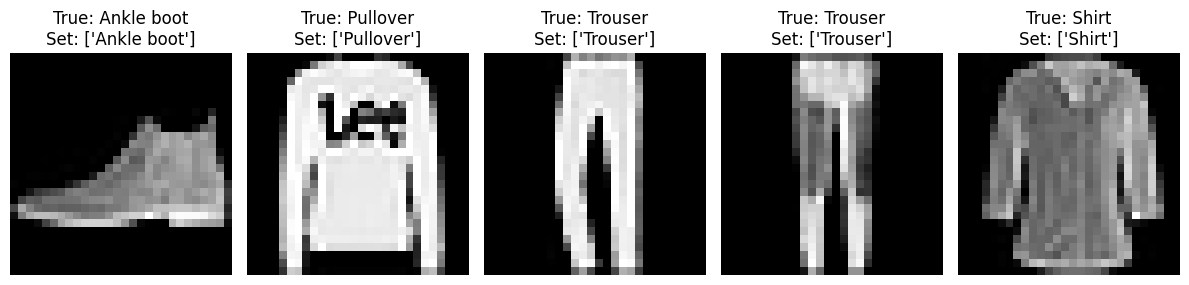

In [ ]:
plt.figure(figsize=(12, 4))

for j, idx in enumerate(singleton_indices[:5]):
    plt.subplot(1, 5, j + 1)

    plt.imshow(X_test[idx].squeeze(), cmap="gray")

    labels_in_set = np.where(sets_90[idx])[0]

    set_names = [
        class_names[k] for k in labels_in_set
    ]

    plt.title(
        f"True: {class_names[y_test[idx]]}\n"
        f"Set: {set_names}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
multi_indices = np.where(set_size_90 >= 2)[0]

print("Number of multi-label predictions:", len(multi_indices))

Number of multi-label predictions: 0


In [ ]:
plt.figure(figsize=(12, 4))

for j, idx in enumerate(multi_indices[:5]):
    plt.subplot(1, 5, j + 1)

    plt.imshow(X_test[idx].squeeze(), cmap="gray")

    labels_in_set = np.where(sets_90[idx])[0]

    set_names = [
        class_names[k] for k in labels_in_set
    ]

    plt.title(
        f"True: {class_names[y_test[idx]]}\n"
        f"Set: {set_names}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

<Figure size 1200x400 with 0 Axes>

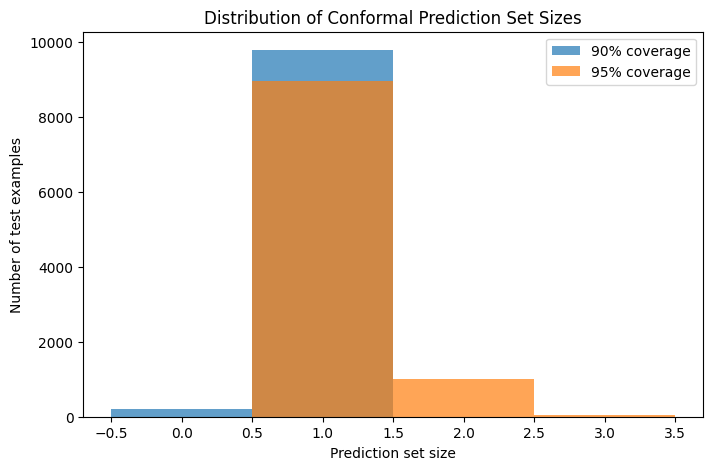

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(
    set_size_90,
    bins=np.arange(-0.5, np.max(set_size_90) + 1.5, 1),
    alpha=0.7,
    label="90% coverage"
)

plt.hist(
    set_size_95,
    bins=np.arange(-0.5, np.max(set_size_95) + 1.5, 1),
    alpha=0.7,
    label="95% coverage"
)

plt.xlabel("Prediction set size")
plt.ylabel("Number of test examples")
plt.title("Distribution of Conformal Prediction Set Sizes")
plt.legend()
plt.show()

The graph shows the distribution of conformal prediction set sizes. Most predictions are singleton sets, meaning the model can provide one label while maintaining the target coverage. When we increase the target coverage from 90% to 95%, the prediction sets become larger because the method becomes more conservative. This illustrates the trade-off between coverage and prediction-set size.

Conformal prediction achieved empirical coverage close to the desired 90% and 95% levels. Increasing the target coverage from 90% to 95% increased the conformal quantile and consequently produced larger prediction sets. This illustrates the trade-off between coverage and set size: higher coverage provides stronger uncertainty guarantees but generally requires less specific predictions.

In [ ]:
def create_cnn():
    model = models.Sequential([
        layers.Conv2D(
            32, (3, 3),
            activation="relu",
            input_shape=(28, 28, 1)
        ),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            64, (3, 3),
            activation="relu"
        ),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),

        layers.Dense(
            128,
            activation="relu"
        ),

        # Logits
        layers.Dense(10)
    ])

    return model

In [ ]:
ensemble_models = []

for i in range(3):

    model = create_cnn()

    model.compile(
        optimizer="adam",
        loss=tf.keras.losses.SparseCategoricalCrossentropy(
            from_logits=True
        ),
        metrics=["accuracy"]
    )

    ensemble_models.append(model)

    print(f"Model {i+1} created")

Model 1 created
Model 2 created
Model 3 created


In [ ]:
for i, model in enumerate(ensemble_models):

    print(f"\nTraining model {i+1}/3")

    model.fit(
        X_train,
        y_train,
        epochs=10,
        batch_size=128,
        validation_data=(X_calib, y_calib),
        verbose=1
    )


Training model 1/3
Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.7912 - loss: 0.5782 - val_accuracy: 0.8391 - val_loss: 0.4300
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8647 - loss: 0.3699 - val_accuracy: 0.8751 - val_loss: 0.3448
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8844 - loss: 0.3186 - val_accuracy: 0.8823 - val_loss: 0.3241
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8958 - loss: 0.2861 - val_accuracy: 0.8881 - val_loss: 0.3100
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9036 - loss: 0.2637 - val_accuracy: 0.8960 - val_loss: 0.2927
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9128 - loss: 0.2397 - val_accuracy: 0.9005 - val_loss: 0.2774
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9175 - loss: 0.2247 - val_accuracy: 0.9038 - val_loss: 0.2662
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9238 - loss: 0.207